In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Image, display

from data_analysis.config import load_config

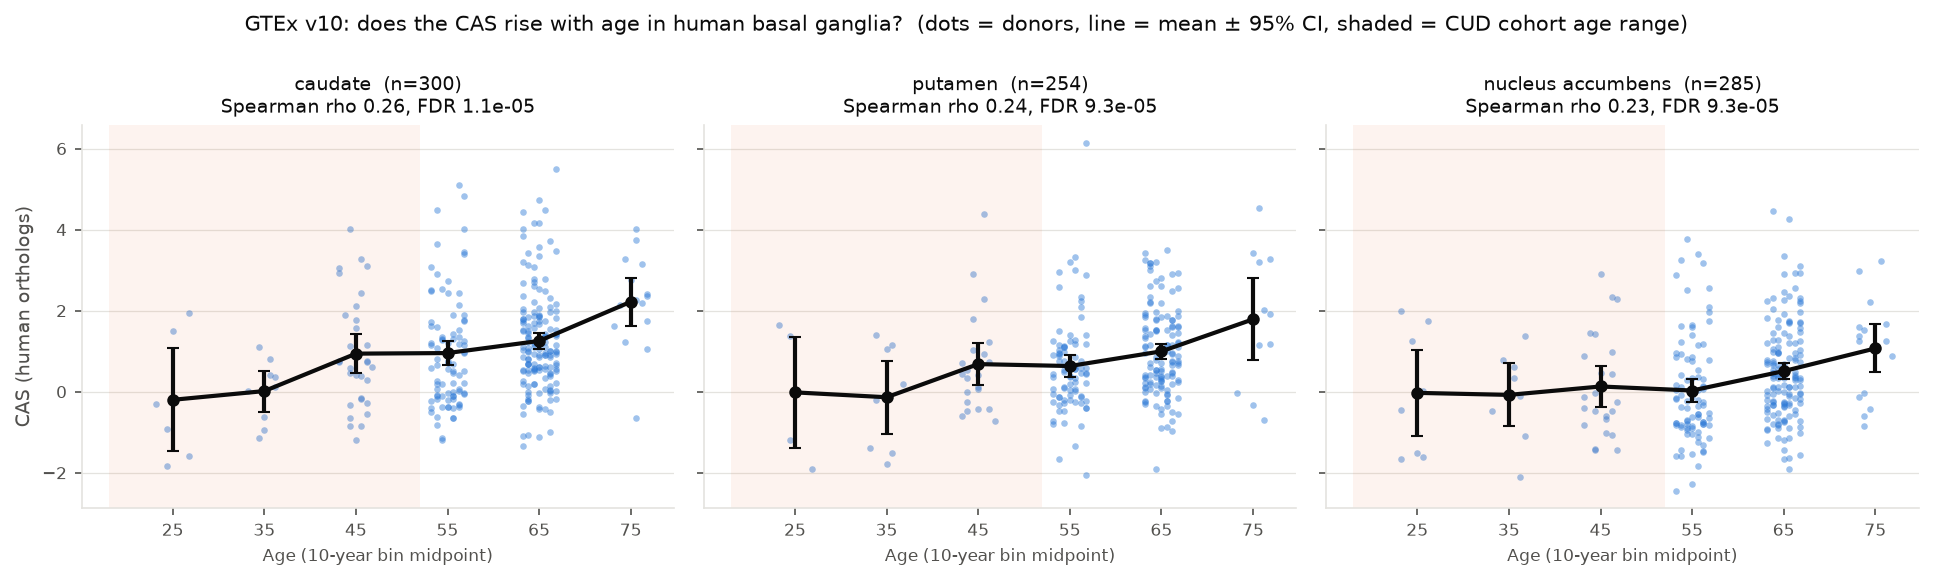

{'rule': 'rho > 0 and FDR < 0.05 in >= 2 of 3 tissues',
 'tissues_passing': 3,
 'human_cas_tracks_age': True}

In [3]:
cfg = load_config()
tables, figs = cfg["paths"]["tables"], cfg["paths"]["figures"]
scores = pd.read_csv(tables / "gtex_cas_scores.csv")
display(Image(figs / "fig_gtex_age_control.png"))
json.loads((tables / "gtex_age_control_verdict.json").read_text())

In [4]:
pd.read_csv(tables / "table_gtex_age_control.csv").round(4)

,region,subset,n,rho,p,fdr
0,caudate,all ages,300,0.2639,0.0000,0.0000
1,caudate,20-49 (CUD cohort range),46,0.3380,0.0216,0.0647
2,putamen,all ages,254,0.2428,0.0001,0.0001
3,putamen,20-49 (CUD cohort range),35,0.1827,0.2936,0.4404
4,nucleus_accumbens,all ages,285,0.2300,0.0001,0.0001
5,nucleus_accumbens,20-49 (CUD cohort range),40,0.0616,0.7056,0.7056


In [5]:
pd.read_csv(tables / "table_gtex_age_models.csv").round(4)

,model,n,age_coef_per_year,ci_low,ci_high,p,per_decade_sd,converged
0,OLS caudate,300,0.0273,0.0124,0.0421,0.0004,NaN,NaN
1,OLS putamen,254,0.0264,0.0105,0.0423,0.0012,NaN,NaN
2,OLS nucleus_accumbens,285,0.0159,0.0011,0.0308,0.0359,NaN,NaN
3,"Mixed (donor random intercept), all tissues, C...",839,0.0179,0.0085,0.0273,0.0002,0.1792,True


In [6]:
scores.groupby(["region", "age_bin"])["cas"].agg(["mean", "count"]).round(2).unstack(0)

mean                             count                          
region  caudate nucleus_accumbens putamen caudate nucleus_accumbens putamen
age_bin                                                                    
20-29     -0.20             -0.03   -0.02       6                 8       5
30-39      0.02             -0.08   -0.14       9                 8       8
40-49      0.94              0.13    0.68      31                24      22
50-59      0.95              0.03    0.63      86                88      82
60-69      1.25              0.51    1.00     153               141     126
70-79      2.22              1.07    1.79      15                16      11

In [7]:
cud = pd.read_csv(tables / "human_cas_scores.csv")
cud["age_bin"] = pd.cut(cud["age"], [17, 29, 39, 49, 59], labels=["20-29", "30-39", "40-49", "50-59"])
cud.query("diagnosis == 'Control'").groupby(["region", "age_bin"], observed=True)["cas"].agg(["mean", "count"]).round(2)

mean  count
region  age_bin             
Caudate 20-29   -0.73      8
        30-39   -1.06      4
        40-49   -1.18      5
        50-59   -1.02      3
NAc     20-29   -0.98      8
        30-39   -0.85      4
        40-49   -1.33      4
        50-59   -1.36      3

In [8]:
pd.crosstab(scores.drop_duplicates("subject_id")["age_bin"],
            scores.drop_duplicates("subject_id")["hardy"])

hardy,0,1,2,3,4
age_bin,,,,,
20-29,0,5,2,1,0
30-39,1,4,2,0,2
40-49,1,3,17,3,7
50-59,2,3,67,7,23
60-69,11,4,88,20,50
70-79,2,2,8,0,7


In [12]:
pd.read_csv(tables / "table_gtex_age_hardy_sensitivity.csv").round(3)

,subset,region,n,rho,p,age_coef_per_year,age_p
0,all donors,caudate,300,0.264,0.000,0.034,0.000
1,all donors,putamen,254,0.243,0.000,0.028,0.001
2,all donors,nucleus_accumbens,285,0.230,0.000,0.020,0.010
3,excluding ventilator deaths (Hardy 0),caudate,288,0.268,0.000,0.034,0.000
4,excluding ventilator deaths (Hardy 0),putamen,243,0.251,0.000,0.031,0.000
5,excluding ventilator deaths (Hardy 0),nucleus_accumbens,269,0.240,0.000,0.020,0.009
6,fast deaths only (Hardy 1-2),caudate,179,0.329,0.000,0.034,0.000
7,fast deaths only (Hardy 1-2),putamen,164,0.264,0.001,0.029,0.002
8,fast deaths only (Hardy 1-2),nucleus_accumbens,173,0.254,0.001,0.016,0.082
9,fast natural deaths only (Hardy 2),caudate,161,0.277,0.000,0.029,0.008
